import pandas 

In [56]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import lightgbm as lgb
warnings.filterwarnings('ignore')
D = 'data/'   # change if your files are somewhere else
train = pd.read_csv('train-test.csv', parse_dates=['date'])
valid = pd.read_csv('validation.csv',  parse_dates=['date'])
print(train.shape, valid.shape)
print('train dates:', train.date.min().date(), '->', train.date.max().date())
print('valid dates:', valid.date.min().date(), '->', valid.date.max().date())
train.head()

(48000, 14) (12000, 13)
train dates: 2025-01-01 -> 2025-10-31
valid dates: 2025-11-01 -> 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


In [57]:
print(train.isna().sum()[lambda s: s > 0], '\n')
print('negative weights:', (train.weight < 0).sum())
print('duplicate load_id:', train.load_id.duplicated().sum())
train[['distance', 'weight', 'posted_rate']].describe().round(1)

weight          300
market_index    374
dtype: int64 

negative weights: 292
duplicate load_id: 0


,distance,weight,posted_rate
count,48000.0,47700.0,48000.0
mean,1135.9,31028.8,2374.0
std,728.6,9391.4,1486.5
min,70.0,-47500.0,57.2
25%,550.4,25800.0,1251.6
50%,953.3,31436.5,2030.8
75%,1645.5,37018.0,3330.8
max,3439.8,47500.0,25533.0


count    48000.00
mean         2.22
std          0.58
min          0.33
1%           1.67
50%          2.15
99%          3.18
max         14.13
Name: rpm, dtype: float64


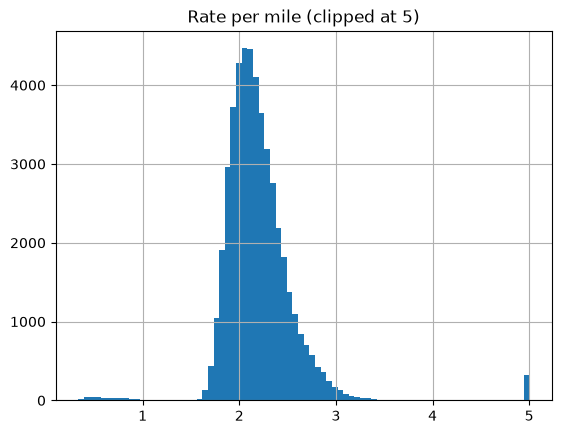

       distance  posted_rate        rpm equipment
22254     314.7      4445.23  14.125294    Reefer
36609      98.4      1386.42  14.089634    Reefer
870       305.6      4069.24  13.315576    Reefer
17070     201.5      2609.34  12.949578   Flatbed
27969     589.9      7597.52  12.879335    Reefer


In [58]:
train['rpm'] = train.posted_rate / train.distance      # dollars per mile
print(train.rpm.describe(percentiles=[.01, .5, .99]).round(2))
train.rpm.clip(0, 5).hist(bins=80); plt.title('Rate per mile (clipped at 5)'); plt.show()
print(train.nlargest(5, 'rpm')[['distance', 'posted_rate', 'rpm', 'equipment']])

distance
(0, 150]        2.87
(150, 300]      2.63
(300, 600]      2.36
(600, 1000]     2.17
(1000, 2000]    2.05
(2000, 4000]    1.91
Name: rpm, dtype: float64 

equipment
Dry Van    2.05
Flatbed    2.22
Reefer     2.31
Name: rpm, dtype: float64


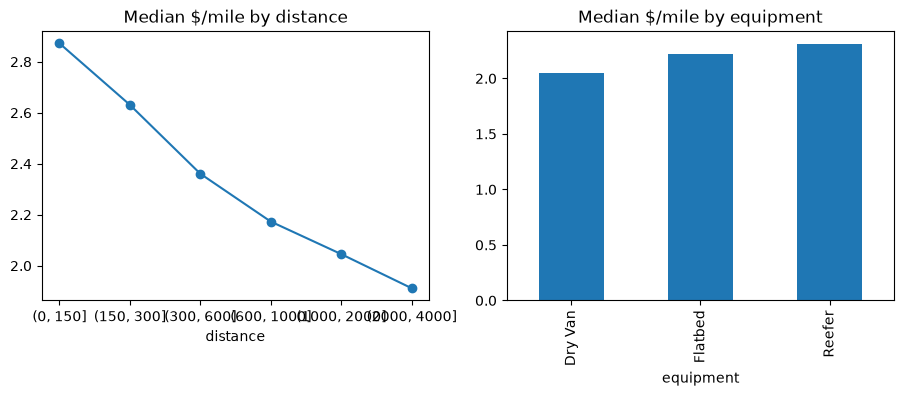

In [59]:
bins = pd.cut(train.distance, [0, 150, 300, 600, 1000, 2000, 4000])
print(train.groupby(bins).rpm.median().round(2), '\n')
print(train.groupby('equipment').rpm.median().round(2))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train.groupby(bins).rpm.median().plot(marker='o', ax=ax[0], title='Median $/mile by distance')
train.groupby('equipment').rpm.median().plot.bar(ax=ax[1], title='Median $/mile by equipment'); plt.show()

In [61]:
train['w'] = train.weight.abs()
print('corr(weight, rpm):', round(train.w.corr(train.rpm), 3))
train['dow'] = train.date.dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
print(train.groupby('dow').rpm.median().reindex(order).round(3))

corr(weight, rpm): 0.093
dow
Monday       2.126
Tuesday      2.139
Wednesday    2.163
Thursday     2.171
Friday       2.157
Saturday     2.132
Sunday       2.127
Name: rpm, dtype: float64


In [62]:
train['month'] = train.date.dt.month
chk = train.groupby('month').apply(lambda g: pd.Series({
    'corr(quote_signal, rpm)': g.quote_signal.corr(g.rpm),
    'corr(market_index, rpm)': g.market_index.corr(g.rpm)})).round(2)
print(chk)

       corr(quote_signal, rpm)  corr(market_index, rpm)
month                                                  
1                         0.45                     0.04
2                         0.48                     0.04
3                         0.49                     0.06
4                        -0.47                     0.07
5                        -0.46                     0.04
6                         0.48                     0.03
7                        -0.47                     0.07
8                        -0.01                     0.03
9                         0.48                     0.02
10                       -0.43                     0.06


In [63]:
# In validation, does quote_signal still relate to distance the way it did in the 'good' months?
def q_dist(g): return np.log(g.distance).corr(g.quote_signal)
print('train months  :', train.groupby('month').apply(q_dist).round(2).to_dict())
print('valid (Nov/Dec):', valid.groupby(valid.date.dt.month).apply(q_dist).round(2).to_dict())

train months  : {1: -0.82, 2: -0.82, 3: -0.79, 4: 0.81, 5: 0.82, 6: -0.8, 7: 0.81, 8: 0.02, 9: -0.8, 10: 0.82}
valid (Nov/Dec): {11: 0.01, 12: 0.01}


In [64]:
tr = train[train.date <  '2025-09-01']
te = train[train.date >= '2025-09-01']
print(len(tr), 'train rows |', len(te), 'holdout rows')

38477 train rows | 9523 holdout rows


In [65]:
EQ = {'Dry Van': 0, 'Reefer': 1, 'Flatbed': 2}
def make(d, cols):
    X = pd.DataFrame(index=d.index)
    X['dist'] = d.distance; X['logd'] = np.log(d.distance)
    X['eq'] = d.equipment.map(EQ)
    if 'weight' in cols: X['w'] = d.weight.abs()
    if 'geo' in cols:
        for c in ['pickup_lat','pickup_lon','delivery_lat','delivery_lon']: X[c] = d[c]
    if 'dow' in cols: X['dow'] = d.date.dt.dayofweek
    if 'market_index' in cols: X['mi'] = d.market_index
    if 'quote_signal' in cols: X['qs'] = d.quote_signal
    return X

def model():
    return lgb.LGBMRegressor(n_estimators=600, learning_rate=0.03, num_leaves=15, min_child_samples=60,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             objective='huber', alpha=0.5, verbose=-1)

def score(cols):
    m = model().fit(make(tr, cols), tr.rpm)
    pred = m.predict(make(te, cols)) * te.distance          # back to dollars
    err = (pred - te.posted_rate).abs()
    return round(err.mean(), 1), round((err / te.posted_rate).mean() * 100, 2)

experiments = {
  'distance + equipment (baseline)': [],
  '+ weight':                        ['weight'],
  '+ weight + geography':            ['weight', 'geo'],
  '+ weight + geo + weekday':        ['weight', 'geo', 'dow'],
  '+ market_index (test)':           ['weight', 'geo', 'dow', 'market_index'],
  '+ quote_signal (test)':           ['weight', 'geo', 'dow', 'quote_signal'],
}
res = pd.DataFrame({k: score(v) for k, v in experiments.items()}, index=['MAE $', 'MAPE %']).T
res

,MAE $,MAPE %
distance + equipment (baseline),132.2,5.92
+ weight,114.5,5.21
+ weight + geography,100.4,4.40
+ weight + geo + weekday,97.8,4.31
+ market_index (test),169.1,7.13
+ quote_signal (test),90.8,3.93


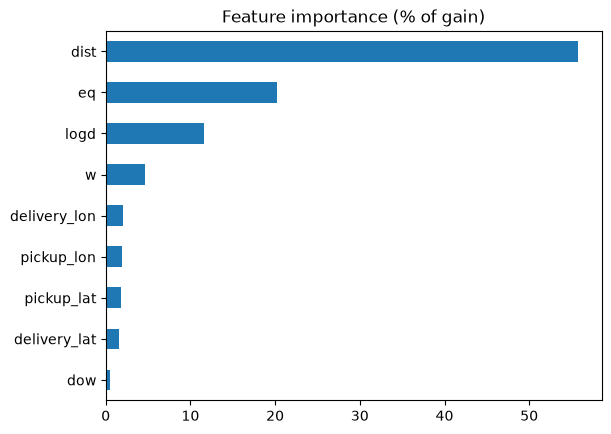

In [66]:
cols = ['weight', 'geo', 'dow']
Xtr = make(tr, cols); m = model().fit(Xtr, tr.rpm)
imp = pd.Series(m.booster_.feature_importance('gain'), Xtr.columns)
(imp / imp.sum() * 100).sort_values().plot.barh(title='Feature importance (% of gain)'); plt.show()

# ------

In [67]:
full = make(train, cols); final = model().fit(full, train.rpm)
valid['predicted_rate'] = (final.predict(make(valid, cols)) * valid.distance).round(2)
out = valid[['load_id', 'predicted_rate']]
out.to_csv('validation_predictions.csv', index=False)
print(out.shape, out.predicted_rate.isna().sum(), 'missing')
out.head()

(12000, 2) 0 missing


,load_id,predicted_rate
0,TE-000001,848.59
1,TE-000002,5080.07
2,TE-000003,5161.56
3,TE-000004,3998.35
4,TE-000005,1848.16


In [68]:
from sklearn.cluster import KMeans
cities = pd.concat([
    train[['pickup','pickup_lat','pickup_lon']].set_axis(['city','lat','lon'], axis=1),
    train[['delivery','delivery_lat','delivery_lon']].set_axis(['city','lat','lon'], axis=1)]).drop_duplicates('city')
print(len(cities), 'unique cities')

def zone_features(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(cities[['lat','lon']])
    zmap = dict(zip(cities.city, km.labels_))
    def f(d):
        X = make2(d)
        X['pz'] = d.pickup.map(zmap); X['dz'] = d.delivery.map(zmap)
        X['lane_zone'] = X['pz'] * k + X['dz']
        return X
    return f

for k in [6, 10, 15]:
    print(f'zones k={k}:', run(zone_features(k)))

64 unique cities
zones k=6: (np.float64(97.82), np.float64(4.311))
zones k=10: (np.float64(97.87), np.float64(4.313))
zones k=15: (np.float64(98.0), np.float64(4.315))


In [70]:

from catboost import CatBoostRegressor
Xa, Xb = make2(tr), make2(te)
m_lgb = model().fit(Xa, tr.rpm)
m_cb  = CatBoostRegressor(iterations=1500, learning_rate=0.05, depth=6, loss_function='MAE',
                          verbose=0, random_seed=0).fit(Xa, tr.rpm)
p_lgb = m_lgb.predict(Xb) * te.distance
p_cb  = m_cb.predict(Xb)  * te.distance
def mae(p): e = (p - te.posted_rate).abs(); return round(e.mean(), 2), round((e / te.posted_rate).mean() * 100, 3)
print('LightGBM        :', mae(p_lgb))
print('CatBoost (MAE)  :', mae(p_cb))
print('50/50 blend     :', mae((p_lgb + p_cb) / 2))

LightGBM        : (np.float64(97.82), np.float64(4.31))
CatBoost (MAE)  : (np.float64(98.46), np.float64(4.324))
50/50 blend     : (np.float64(97.61), np.float64(4.296))


In [5]:
data.groupby('pickup')[['pickup_lat', 'pickup_lon']].nunique().sort_values(
    ['pickup_lat', 'pickup_lon'], ascending=False
).head(10)

,pickup_lat,pickup_lon
pickup,,
Albany,1,1
Albuquerque,1,1
Amarillo,1,1
Atlanta,1,1
Austin,1,1
Bakersfield,1,1
Baltimore,1,1
Baton Rouge,1,1
Birmingham,1,1


In [60]:
train['w'] = train.weight.abs()
print('corr(weight, rpm):', round(train.w.corr(train.rpm), 3))
train['dow'] = train.date.dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
print(train.groupby('dow').rpm.median().reindex(order).round(3))

corr(weight, rpm): 0.093
dow
Monday       2.126
Tuesday      2.139
Wednesday    2.163
Thursday     2.171
Friday       2.157
Saturday     2.132
Sunday       2.127
Name: rpm, dtype: float64


In [7]:
print(data.dtypes)

load_id             str
pickup              str
delivery            str
pickup_lat      float64
pickup_lon      float64
delivery_lat    float64
delivery_lon    float64
distance        float64
equipment           str
weight          float64
date                str
market_index    float64
quote_signal    float64
posted_rate     float64
dtype: object


In [8]:
data['date'] = pd.to_datetime(data['date'])

print(data['date'].min())
print(data['date'].max())
print(data['date'].nunique())
print(data['posted_rate'].describe())
print(data.isnull().sum())

2025-01-01 00:00:00
2025-10-31 00:00:00
304
count    48000.000000
mean      2373.980682
std       1486.493245
min         57.220000
25%       1251.555000
50%       2030.760000
75%       3330.750000
max      25533.000000
Name: posted_rate, dtype: float64
load_id           0
pickup            0
delivery          0
pickup_lat        0
pickup_lon        0
delivery_lat      0
delivery_lon      0
distance          0
equipment         0
weight          300
date              0
market_index    374
quote_signal      0
posted_rate       0
dtype: int64


### step1

In [9]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
import lightgbm as lgb
warnings.filterwarnings('ignore')

In [10]:
D = 'data/'   # change if your files are somewhere else
train = pd.read_csv( 'train-test.csv', parse_dates=['date'])
valid = pd.read_csv('validation.csv',  parse_dates=['date'])
print(train.shape, valid.shape)
print('train dates:', train.date.min().date(), '->', train.date.max().date())
print('valid dates:', valid.date.min().date(), '->', valid.date.max().date())
train.head()

(48000, 14) (12000, 13)
train dates: 2025-01-01 -> 2025-10-31
valid dates: 2025-11-01 -> 2025-12-31


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.09122,-76.78906,38.16908,-72.74564,274.3,Dry Van,30658.0,2025-01-01,0.95684,2.39595,645.41
1,TR-000002,Richmond,Philadelphia,38.09122,-76.78906,39.22317,-72.96710,280.5,Reefer,17555.0,2025-01-01,0.97623,2.43355,679.97
2,TR-000003,Philadelphia,Green Bay,39.22317,-72.96710,44.30296,-87.52871,967.8,Dry Van,31721.0,2025-01-01,1.00971,1.84491,1802.54
3,TR-000004,Hartford,Atlanta,39.55328,-72.18051,34.84933,-86.28940,965.4,Dry Van,32333.0,2025-01-01,0.94518,1.87712,1827.28
4,TR-000005,Dallas,Nashville,31.83025,-94.38343,35.29479,-88.08915,541.9,Reefer,35183.0,2025-01-01,0.98480,2.56300,1380.28


### stpe2

In [11]:
print(train.isna().sum()[lambda s : s> 0])
print('----------')
print('negative weights:', (train.weight < 0).sum())
print('----------')
print('duplicate load_id:', train.load_id.duplicated().sum())
print('----------')
train[['distance', 'weight', 'posted_rate']].describe().round(1)

weight          300
market_index    374
dtype: int64
----------
negative weights: 292
----------
duplicate load_id: 0
----------


,distance,weight,posted_rate
count,48000.0,47700.0,48000.0
mean,1135.9,31028.8,2374.0
std,728.6,9391.4,1486.5
min,70.0,-47500.0,57.2
25%,550.4,25800.0,1251.6
50%,953.3,31436.5,2030.8
75%,1645.5,37018.0,3330.8
max,3439.8,47500.0,25533.0


In [12]:
train['rpm'] = train.posted_rate / train.distance      # dollars per mile
print(train.rpm.describe(percentiles=[.01, .5, .99]).round(2))

count    48000.00
mean         2.22
std          0.58
min          0.33
1%           1.67
50%          2.15
99%          3.18
max         14.13
Name: rpm, dtype: float64


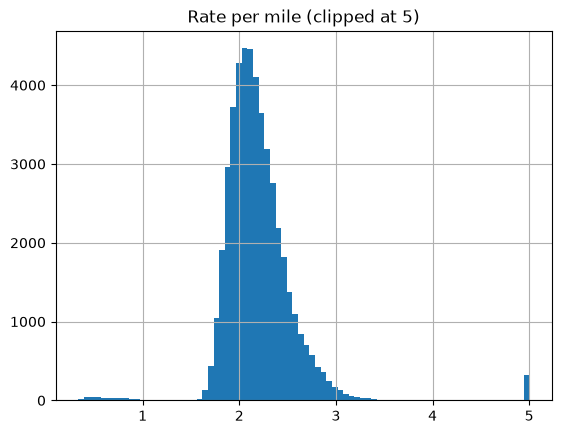

       distance  posted_rate        rpm equipment
22254     314.7      4445.23  14.125294    Reefer
36609      98.4      1386.42  14.089634    Reefer
870       305.6      4069.24  13.315576    Reefer
17070     201.5      2609.34  12.949578   Flatbed
27969     589.9      7597.52  12.879335    Reefer
23369     412.4      5308.96  12.873327   Flatbed
28012     604.3      7773.37  12.863429    Reefer
45483     153.8      1971.21  12.816710   Dry Van
1415      198.2      2509.96  12.663774    Reefer
21968     254.5      3220.66  12.654853   Dry Van


In [14]:

train.rpm.clip(0, 5).hist(bins=80); plt.title('Rate per mile (clipped at 5)'); plt.show()
print(train.nlargest(10, 'rpm')[['distance', 'posted_rate', 'rpm', 'equipment']])

### step3

In [15]:
bins = pd.cut(train.distance, [0, 150, 300, 600, 1000, 2000, 4000])
print(train.groupby(bins).rpm.median().round(2), '\n')
print(train.groupby('equipment').rpm.median().round(2))

distance
(0, 150]        2.87
(150, 300]      2.63
(300, 600]      2.36
(600, 1000]     2.17
(1000, 2000]    2.05
(2000, 4000]    1.91
Name: rpm, dtype: float64 

equipment
Dry Van    2.05
Flatbed    2.22
Reefer     2.31
Name: rpm, dtype: float64


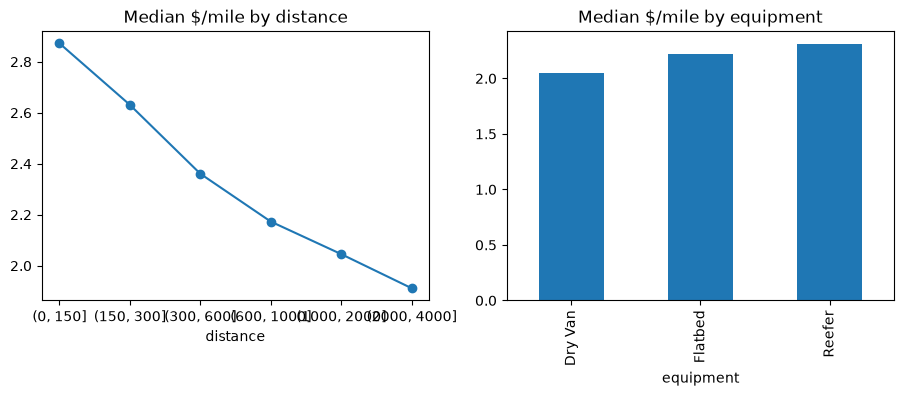

In [15]:

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
train.groupby(bins).rpm.median().plot(marker='o', ax=ax[0], title='Median $/mile by distance')
train.groupby('equipment').rpm.median().plot.bar(ax=ax[1], title='Median $/mile by equipment'); plt.show()

#### step 4


In [16]:
train['w'] = train.weight.abs()
print('corr(weight, rpm):', round(train.w.corr(train.rpm), 3))
train['dow'] = train.date.dt.day_name()
order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
print(train.groupby('dow').rpm.median().reindex(order).round(3))

corr(weight, rpm): 0.093
dow
Monday       2.126
Tuesday      2.139
Wednesday    2.163
Thursday     2.171
Friday       2.157
Saturday     2.132
Sunday       2.127
Name: rpm, dtype: float64


### step5


In [18]:
train['month'] = train.date.dt.month
chk = train.groupby('month').apply(lambda g: pd.Series({
    'corr(quote_signal, rpm)': g.quote_signal.corr(g.rpm),
    'corr(market_index, rpm)': g.market_index.corr(g.rpm)})).round(2)
print(chk)

       corr(quote_signal, rpm)  corr(market_index, rpm)
month                                                  
1                         0.45                     0.04
2                         0.48                     0.04
3                         0.49                     0.06
4                        -0.47                     0.07
5                        -0.46                     0.04
6                         0.48                     0.03
7                        -0.47                     0.07
8                        -0.01                     0.03
9                         0.48                     0.02
10                       -0.43                     0.06


In [19]:
# In validation, does quote_signal still relate to distance the way it did in the 'good' months?
def q_dist(g): return np.log(g.distance).corr(g.quote_signal)
print('train months  :', train.groupby('month').apply(q_dist).round(2).to_dict())
print('valid (Nov/Dec):', valid.groupby(valid.date.dt.month).apply(q_dist).round(2).to_dict())

train months  : {1: -0.82, 2: -0.82, 3: -0.79, 4: 0.81, 5: 0.82, 6: -0.8, 7: 0.81, 8: 0.02, 9: -0.8, 10: 0.82}
valid (Nov/Dec): {11: 0.01, 12: 0.01}


### step 6

In [24]:
tr = train[train.date <  '2025-09-01']
te = train[train.date >= '2025-09-01']
print(len(tr), 'train rows |', len(te), 'holdout rows')

38477 train rows | 9523 holdout rows


### step7

In [45]:
EQ = {'Dry Van': 0, 'Reefer': 1, 'Flatbed': 2}
def make(d, cols):
    X = pd.DataFrame(index=d.index)
    X['dist'] = d.distance; X['logd'] = np.log(d.distance)
    X['eq'] = d.equipment.map(EQ)
    if 'weight' in cols: X['w'] = d.weight.abs()
    if 'geo' in cols:
        for c in ['pickup_lat','pickup_lon','delivery_lat','delivery_lon']: X[c] = d[c]
    if 'dow' in cols: X['dow'] = d.date.dt.dayofweek
    if 'market_index' in cols: X['mi'] = d.market_index
    if 'quote_signal' in cols: X['qs'] = d.quote_signal
    return X

def model():
    return lgb.LGBMRegressor(
    n_estimators=600, learning_rate=0.03,
    num_leaves=15, min_child_samples=60,
    subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
    objective='huber', alpha=0.5, verbose=-1)

def score(cols):
    m = model().fit(make(tr, cols), tr.rpm)
    pred = m.predict(make(te, cols)) * te.distance          # back to dollars
    err = (pred - te.posted_rate).abs()
    return round(err.mean(), 1), round((err / te.posted_rate).mean() * 100, 2)

experiments = {
  'distance + equipment (baseline)': [],
  '+ weight':                        ['weight'],
  '+ weight + geography':            ['weight', 'geo'],
  '+ weight + geo + weekday':        ['weight', 'geo', 'dow'],
  '+ market_index (test)':           ['weight', 'geo', 'dow', 'market_index'],
  '+ quote_signal (test)':           ['weight', 'geo', 'dow', 'quote_signal'],
}
res = pd.DataFrame({k: score(v) for k, v in experiments.items()}, index=['MAE $', 'MAPE %']).T
res

,MAE $,MAPE %
distance + equipment (baseline),132.2,5.92
+ weight,114.5,5.21
+ weight + geography,100.4,4.40
+ weight + geo + weekday,97.8,4.31
+ market_index (test),169.1,7.13
+ quote_signal (test),90.8,3.93


### stpe 8

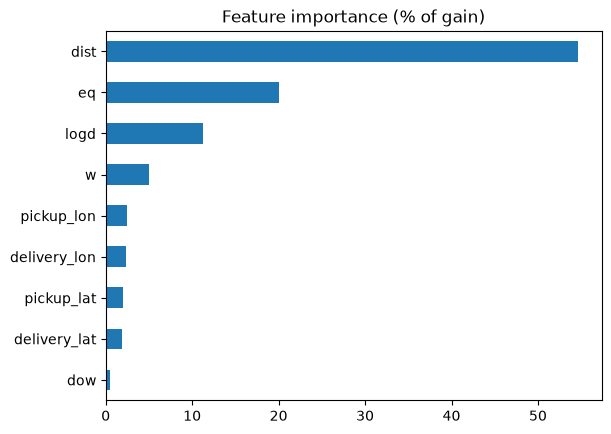

In [29]:
cols = ['weight', 'geo', 'dow']
Xtr = make(tr, cols); m = model().fit(Xtr, tr.rpm)
imp = pd.Series(m.booster_.feature_importance('gain'), Xtr.columns)
(imp / imp.sum() * 100).sort_values().plot.barh(title='Feature importance (% of gain)'); plt.show()

### step 9

In [30]:
full = make(train, cols); final = model().fit(full, train.rpm)
valid['predicted_rate'] = (final.predict(make(valid, cols)) * valid.distance).round(2)
out = valid[['load_id', 'predicted_rate']]
out.to_csv('validation_predictions.csv', index=False)
print(out.shape, out.predicted_rate.isna().sum(), 'missing')
out.head()

(12000, 2) 0 missing


,load_id,predicted_rate
0,TE-000001,840.64
1,TE-000002,5108.49
2,TE-000003,5180.07
3,TE-000004,3999.69
4,TE-000005,1844.90


### Stepp 10

In [46]:
def make2(d, extra=()):
    X = make(d, ['weight', 'geo', 'dow'])
    if 'eq_x_dist' in extra:
        X['eq_x_logd'] = X['eq'] * X['logd']
        X['reefer'] = (X['eq'] == 1).astype(int); X['flatbed'] = (X['eq'] == 2).astype(int)
        X['reefer_x_logd'] = X['reefer'] * X['logd']; X['flatbed_x_logd'] = X['flatbed'] * X['logd']
    return X

def run(make_fn, train_df=None, test_df=None, **kw):
    a = tr if train_df is None else train_df
    b = te if test_df is None else test_df
    m = model().fit(make_fn(a, **kw), a.rpm)
    err = (m.predict(make_fn(b, **kw)) * b.distance - b.posted_rate).abs()
    return round(err.mean(), 2), round((err / b.posted_rate).mean() * 100, 3)

print('reference (Step 7)       :', run(make2))
print('+ equipment x distance   :', run(make2, extra=('eq_x_dist',)))

reference (Step 7)       : (np.float64(97.82), np.float64(4.31))
+ equipment x distance   : (np.float64(97.93), np.float64(4.317))


In [47]:
from sklearn.cluster import KMeans
cities = pd.concat([
    train[['pickup','pickup_lat','pickup_lon']].set_axis(['city','lat','lon'], axis=1),
    train[['delivery','delivery_lat','delivery_lon']].set_axis(['city','lat','lon'], axis=1)]).drop_duplicates('city')
print(len(cities), 'unique cities')

def zone_features(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(cities[['lat','lon']])
    zmap = dict(zip(cities.city, km.labels_))
    def f(d):
        X = make2(d)
        X['pz'] = d.pickup.map(zmap); X['dz'] = d.delivery.map(zmap)
        X['lane_zone'] = X['pz'] * k + X['dz']
        return X
    return f

for k in [6, 10, 15]:
    print(f'zones k={k}:', run(zone_features(k)))

64 unique cities
zones k=6: (np.float64(97.82), np.float64(4.311))
zones k=10: (np.float64(97.87), np.float64(4.313))
zones k=15: (np.float64(98.0), np.float64(4.315))


In [48]:
def add_lane_feature(tr_df, te_df, prior=10):
    tr_s = tr_df.sort_values('date').copy()
    tr_s['lane'] = tr_s.pickup + '>' + tr_s.delivery
    g = tr_s.groupby('lane').rpm
    csum = g.cumsum() - tr_s.rpm; cnt = g.cumcount()
    gm = tr_s.rpm.mean()
    tr_s['lane_rpm'] = (csum + prior * gm) / (cnt + prior)      # shrink toward global mean
    tr_s['lane_n'] = cnt
    full = tr_s.groupby('lane').rpm.agg(['sum', 'count'])
    te_df = te_df.copy(); te_df['lane'] = te_df.pickup + '>' + te_df.delivery
    s = te_df.lane.map(full['sum']).fillna(0); c = te_df.lane.map(full['count']).fillna(0)
    te_df['lane_rpm'] = (s + prior * gm) / (c + prior); te_df['lane_n'] = c
    return tr_s.sort_index(), te_df

tr_l, te_l = add_lane_feature(tr, te)
def make_lane(d): 
    X = make2(d); X['lane_rpm'] = d.lane_rpm; X['lane_n'] = d.lane_n; return X
print('+ lane average rpm       :', run(make_lane, tr_l, te_l))
print('unseen lanes in holdout  :', round((te_l.lane_n == 0).mean() * 100, 1), '%')

+ lane average rpm       : (np.float64(102.87), np.float64(4.523))
unseen lanes in holdout  : 0.2 %


In [50]:

from catboost import CatBoostRegressor
Xa, Xb = make2(tr), make2(te)
m_lgb = model().fit(Xa, tr.rpm)
m_cb  = CatBoostRegressor(iterations=1500, learning_rate=0.05, depth=6, loss_function='MAE',
                          verbose=0, random_seed=0).fit(Xa, tr.rpm)
p_lgb = m_lgb.predict(Xb) * te.distance
p_cb  = m_cb.predict(Xb)  * te.distance
def mae(p): e = (p - te.posted_rate).abs(); return round(e.mean(), 2), round((e / te.posted_rate).mean() * 100, 3)
print('LightGBM        :', mae(p_lgb))
print('CatBoost (MAE)  :', mae(p_cb))
print('50/50 blend     :', mae((p_lgb + p_cb) / 2))

LightGBM        : (np.float64(97.82), np.float64(4.31))
CatBoost (MAE)  : (np.float64(98.46), np.float64(4.324))
50/50 blend     : (np.float64(97.61), np.float64(4.296))


In [52]:
chart = pd.read_csv( 'december-chart-inputs.csv', parse_dates=['date'])
coords = {}
for d in (train, valid):
    for c_, la, lo in zip(d.pickup, d.pickup_lat, d.pickup_lon): coords[c_] = (la, lo)
    for c_, la, lo in zip(d.delivery, d.delivery_lat, d.delivery_lon): coords[c_] = (la, lo)
chart['pickup_lat'],   chart['pickup_lon']   = zip(*chart.pickup.map(coords))
chart['delivery_lat'], chart['delivery_lon'] = zip(*chart.delivery.map(coords))

cols = ['weight', 'geo', 'dow']
final = model().fit(make(train, cols), train.rpm)
chart['predicted_rate'] = (final.predict(make(chart, cols)) * chart.distance).round(2)
chart[['pickup','delivery','distance','equipment','weight','date','predicted_rate']].to_csv(
    'december_predictions.csv', index=False)
chart.assign(day=chart.date.dt.day_name()).groupby('day').predicted_rate.mean().reindex(order).round(1)

day
Monday       811.6
Tuesday      819.1
Wednesday    825.9
Thursday     827.7
Friday       823.2
Saturday     816.4
Sunday       809.2
Name: predicted_rate, dtype: float64

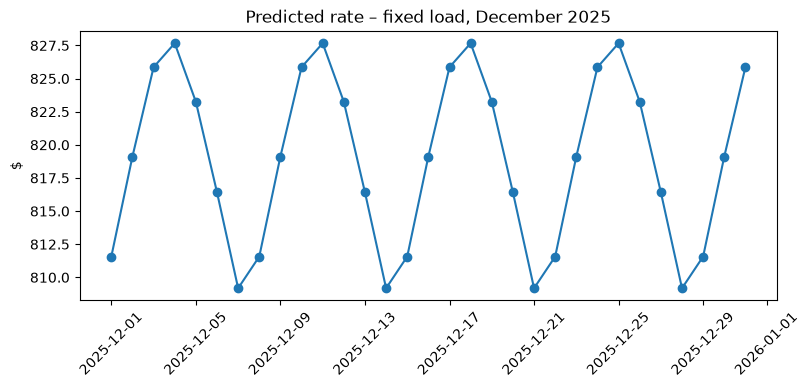

In [53]:
plt.figure(figsize=(9, 3.5))
plt.plot(chart.date, chart.predicted_rate, marker='o')
plt.title('Predicted rate – fixed load, December 2025'); plt.ylabel('$'); plt.xticks(rotation=45); plt.show()